# PlannerLLM: results analysis

This notebook reproduces every table and figure of the evaluation chapter from the raw result files.

* Raw results: `runs/openai_gpt-oss-20b_seed<k>/*.json`, one folder per run seed. A seed fixes the query groups,
  the optimisation and held-out questions, and the validation samples.
* Aggregate: `runs/openai_gpt-oss-20b_aggregate/` (written by `scripts/aggregate_results.py`, rebuilt below).
* Statistics: mean ± sample standard deviation over seeds, 95% t-intervals, paired bootstrap confidence intervals,
  Wilcoxon signed-rank tests with Holm correction, Spearman correlation and Cohen's kappa.

The last cell recomputes the headline numbers from the raw files with separate code and checks them against the
aggregate.

The main analysis uses the original Groq runs cited in the report. The last section shows the separate notebook execution artifacts.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import HTML, Image, display
from plannerllm.eval.aggregate import build, seed_dirs
from plannerllm.settings import RUNS_DIR

TAG = "openai_gpt-oss-20b"
print("seed folders:", [d.name for _, d in seed_dirs(TAG)])
path = build(TAG)
A = json.loads(Path(path).read_text(encoding="utf-8"))
AGG = Path(path).parent
print("model:", A["model"], "| profile:", A["profile"], "| seeds:", A["seeds"])
print("run dates:", A["created"])

seed folders: ['openai_gpt-oss-20b_seed0', 'openai_gpt-oss-20b_seed1', 'openai_gpt-oss-20b_seed2']
model: openai/gpt-oss-20b | profile: quick | seeds: [0, 1, 2]
run dates: {'0': '2026-11-14 05:49:55', '1': '2026-11-14 06:31:19', '2': '2026-11-14 10:39:55'}


In [2]:
WL = {"msmarco": "MS MARCO", "cuad": "CUAD", "spider": "Spider"}
SYS = {"no_opt": "No optimisation", "random": "Random", "cost_only": "Cost-only", "docetl": "DocETL-style",
       "plannerllm": "PlannerLLM", "no_gate": "without VoI gate", "no_memory": "without plan memory",
       "symbolic_only": "symbolic cost only", "neural_only": "neural cost only"}

def ms(x, d=3):
    if not x or x.get("mean") is None:
        return "-"
    return f"{x['mean']:.{d}f} ± {x['std']:.{d}f}" if x["n"] > 1 else f"{x['mean']:.{d}f}"

def num(v, d=3):
    return "-" if v is None else (f"{v:,.0f}" if isinstance(v, (int, float)) and abs(v) >= 1000 else f"{v:.{d}f}")

def table(header, rows):
    h = "".join(f"<th style='text-align:left;padding:2px 10px'>{c}</th>" for c in header)
    b = "".join("<tr>" + "".join(f"<td style='padding:2px 10px'>{c}</td>" for c in r) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{h}</tr></thead><tbody>{b}</tbody></table>"))

## 1. Metrics

Primary held-out metric per workload: Rouge-L for MS MARCO (its official QA metric, β = 1.2), SQuAD-style token F1
for CUAD clause spans, and execution accuracy for Spider. Answers are normalised (lower case, punctuation and
citation markers such as 【1】 removed, articles dropped) before scoring. Execution time is the operators' local time
plus the LLM's server-side service time reported by the API, so cached calls and rate-limit waits do not distort it.

In [3]:
print(A["metric_name"])

{'msmarco': 'Rouge-L', 'cuad': 'token F1', 'spider': 'execution accuracy'}


## 2. Baselines (mean ± sd over seeds)

Workload,System,Score,Opt. tokens / task,Validations,Gate skips,Memory hits,Exec ms / query
MS MARCO,No optimisation,0.226 ± 0.053,0 ± 0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,127 ± 4
MS MARCO,Random,0.237 ± 0.058,0 ± 0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,416 ± 47
MS MARCO,Cost-only,0.223 ± 0.053,1537 ± 7,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,125 ± 7
MS MARCO,DocETL-style,0.229 ± 0.077,97924 ± 11966,16.3 ± 2.5,0.0 ± 0.0,0.0 ± 0.0,499 ± 165
MS MARCO,PlannerLLM,0.218 ± 0.044,32496 ± 4799,4.7 ± 0.6,2.0 ± 1.8,0.0 ± 0.0,127 ± 5
CUAD,No optimisation,0.028 ± 0.048,0 ± 0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,57 ± 8
CUAD,Random,0.028 ± 0.048,0 ± 0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,56 ± 8
CUAD,Cost-only,0.028 ± 0.048,1622 ± 57,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,54 ± 7
CUAD,DocETL-style,0.215 ± 0.106,65042 ± 12773,18.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,181 ± 87
CUAD,PlannerLLM,0.120 ± 0.066,29228 ± 4680,6.8 ± 0.8,1.5 ± 1.0,0.0 ± 0.0,150 ± 65


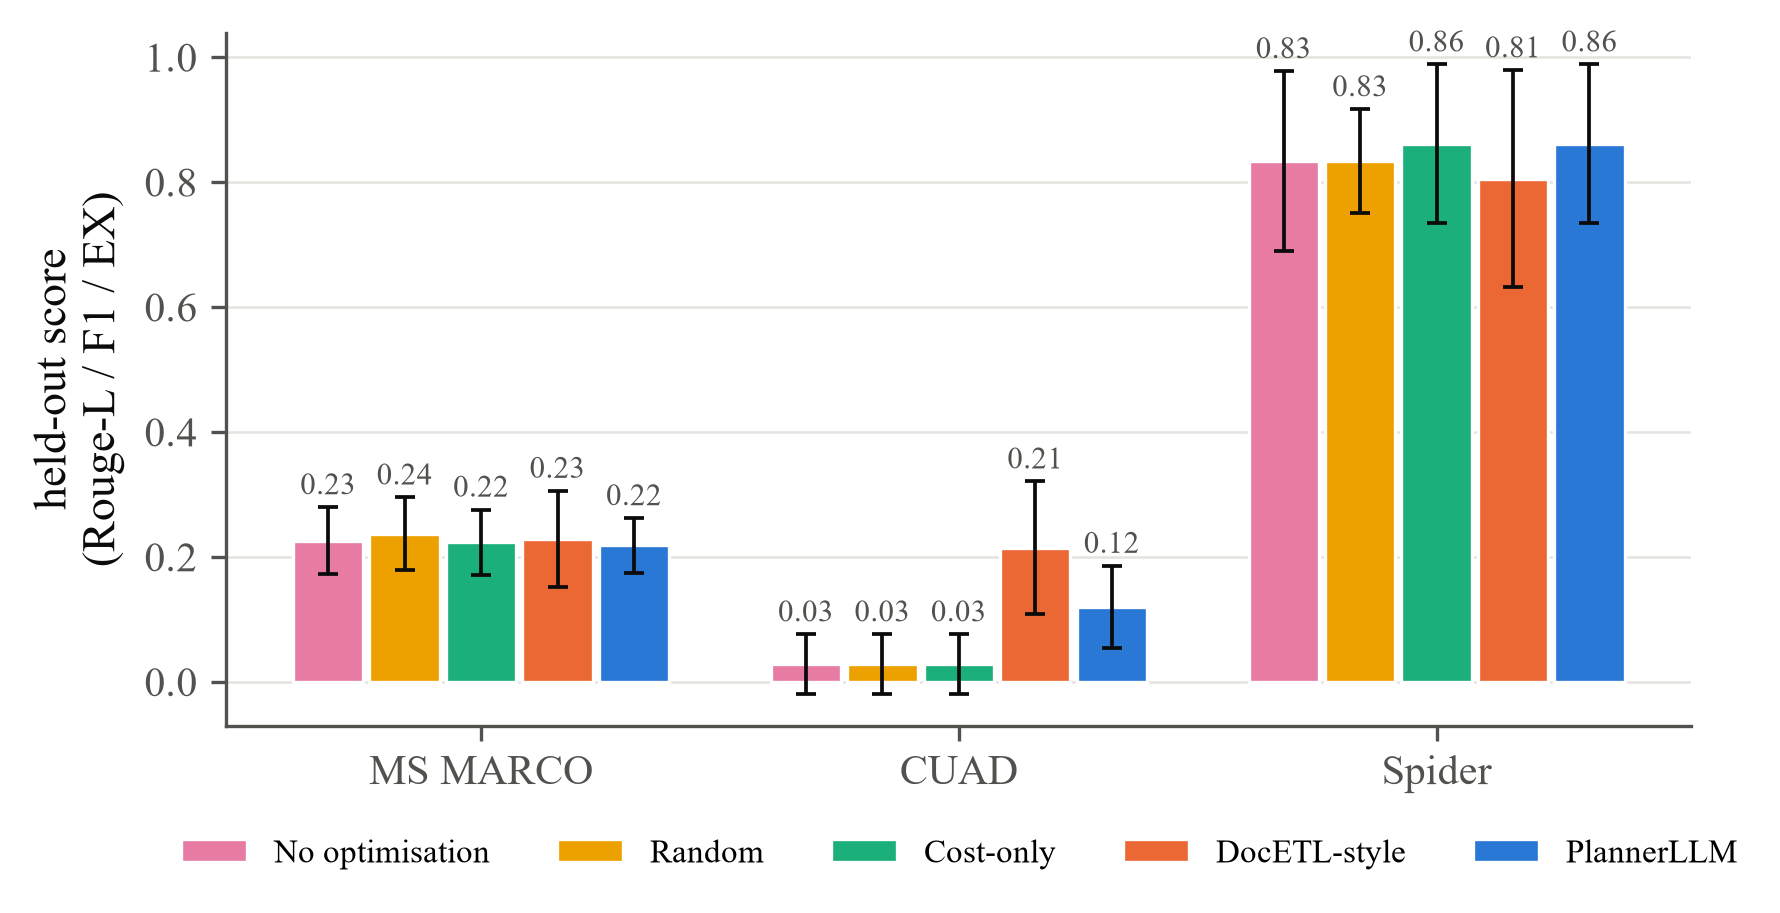

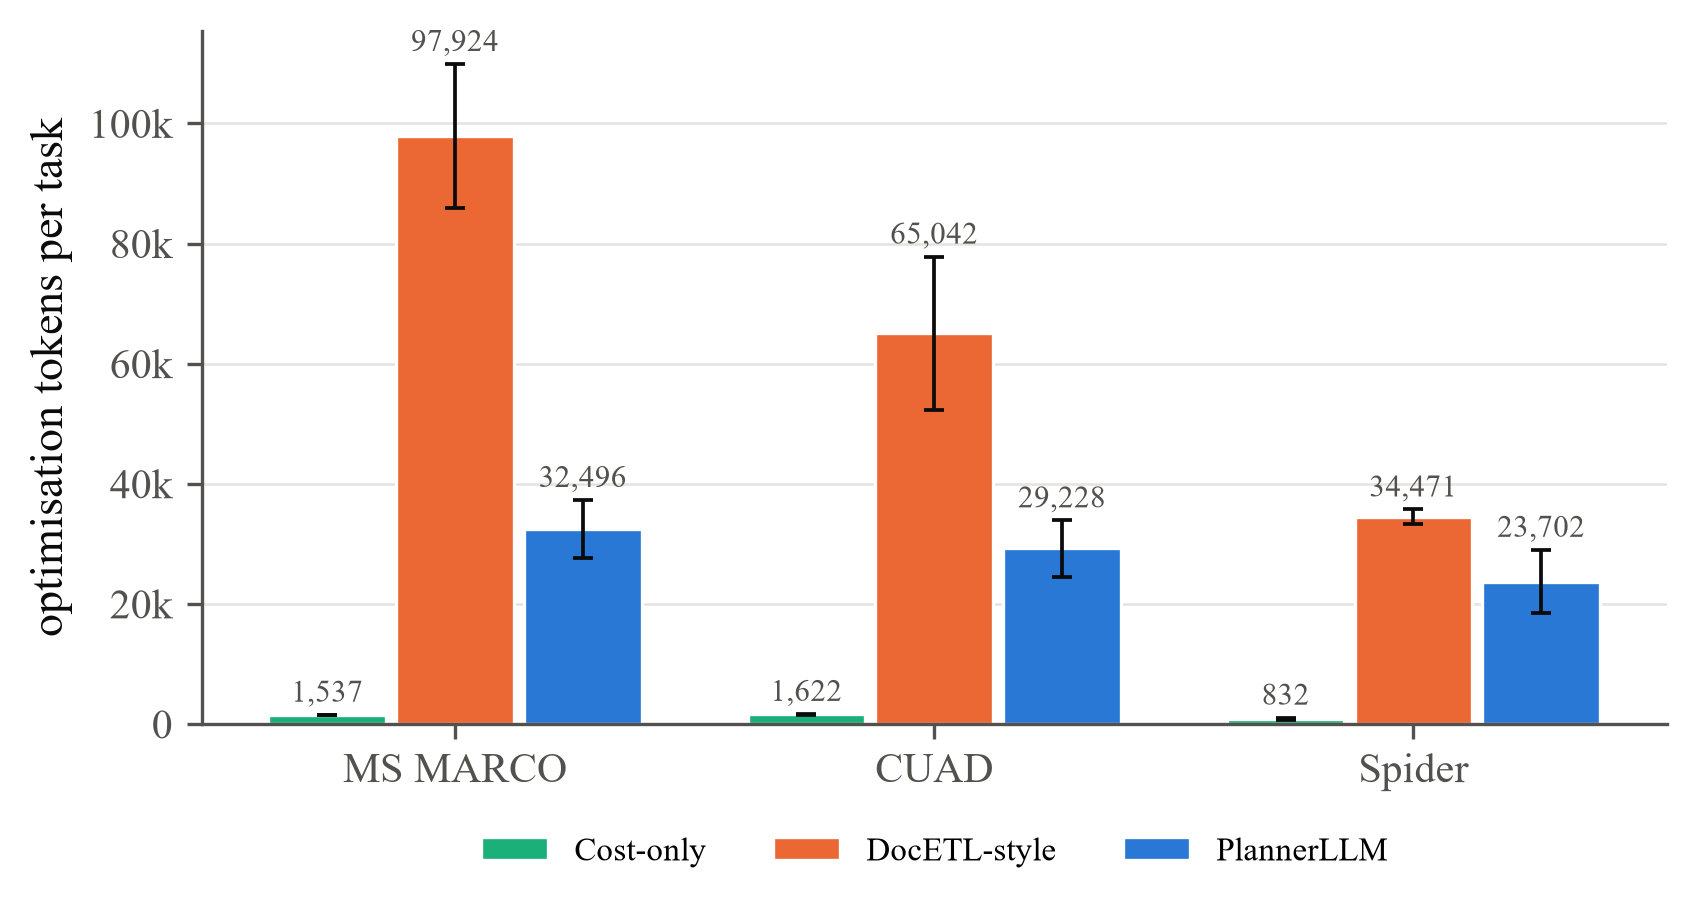

In [4]:
table(["Workload", "System", "Score", "Opt. tokens / task", "Validations", "Gate skips", "Memory hits", "Exec ms / query"],
      [[WL[r["workload"]], SYS[r["system"]], ms(r["accuracy"]), ms(r["opt_tokens"], 0), ms(r["n_validations"], 1),
        ms(r["n_gate_skips"], 1), ms(r["n_memory_hits"], 1), ms(r["exec_ms"], 0)] for r in A["baselines"]])
display(Image(filename=str(AGG / "fig_baselines_accuracy.png"), width=700))
display(Image(filename=str(AGG / "fig_baselines_tokens.png"), width=700))

### Paired tests on held-out questions (PlannerLLM minus baseline)

In [5]:
table(["Workload", "vs", "n", "Mean diff.", "95% CI", "Wilcoxon p", "Holm p", "W / T / L"],
      [[WL[t["workload"]], SYS[t["other"]], t["n"], num(t["mean_diff"]),
        "-" if not t["ci95"] else f"[{t['ci95'][0]:.3f}, {t['ci95'][1]:.3f}]", num(t["p_wilcoxon"]), num(t["p_holm"]),
        f"{t['wins']} / {t['ties']} / {t['losses']}"] for t in A["accuracy_tests"]])

Workload,vs,n,Mean diff.,95% CI,Wilcoxon p,Holm p,W / T / L
MS MARCO,DocETL-style,36,-0.011,"[-0.046, 0.025]",0.256,1.000,4 / 23 / 9
MS MARCO,No optimisation,36,-0.008,"[-0.028, 0.007]",0.558,1.000,1 / 32 / 3
MS MARCO,Cost-only,36,-0.005,"[-0.026, 0.012]",0.785,1.000,2 / 31 / 3
MS MARCO,Random,36,-0.019,"[-0.049, 0.011]",0.113,1.000,5 / 19 / 12
CUAD,DocETL-style,36,-0.095,"[-0.223, 0.028]",0.084,1.000,2 / 25 / 9
CUAD,No optimisation,36,0.092,"[0.017, 0.185]",0.147,1.000,5 / 31 / 0
CUAD,Cost-only,36,0.092,"[0.017, 0.185]",0.147,1.000,5 / 31 / 0
CUAD,Random,36,0.092,"[0.017, 0.185]",0.147,1.000,5 / 31 / 0
Spider,DocETL-style,36,0.056,"[-0.056, 0.167]",0.552,1.000,3 / 32 / 1
Spider,No optimisation,36,0.028,"[0.000, 0.083]",0.749,1.000,1 / 35 / 0


### Optimisation-token reduction against the validate-all optimizer (paired per task)

In [6]:
table(["Workload", "Tasks", "Reduction", "95% CI", "Wilcoxon p", "Per-seed mean ± sd"],
      [[WL.get(t["workload"], "All"), t["n"], f"{t['reduction']:.1%}",
        "-" if not t["ci95"] else f"[{t['ci95'][0]:.1%}, {t['ci95'][1]:.1%}]", num(t["p_wilcoxon"]),
        ms(t["per_seed"])] for t in A["token_reduction"]])

Workload,Tasks,Reduction,95% CI,Wilcoxon p,Per-seed mean ± sd
MS MARCO,6,66.8%,"[54.5%, 74.1%]",0.031,0.665 ± 0.069
CUAD,6,55.1%,"[41.3%, 68.8%]",0.031,0.540 ± 0.113
Spider,6,31.2%,"[0.9%, 53.6%]",0.156,0.313 ± 0.147
All,18,56.7%,"[45.1%, 65.3%]",0.000,0.506 ± 0.035


## 3. Independent judge (different model family)

judge model: qwen/qwen3.8-27b | judge tokens: 113968


Workload,System,Judge score
MS MARCO,No optimisation,0.694 ± 0.087
MS MARCO,Random,0.708 ± 0.072
MS MARCO,Cost-only,0.681 ± 0.064
MS MARCO,DocETL-style,0.667 ± 0.072
MS MARCO,PlannerLLM,0.694 ± 0.087
CUAD,No optimisation,0.028 ± 0.048
CUAD,Random,0.028 ± 0.048
CUAD,Cost-only,0.028 ± 0.048
CUAD,DocETL-style,0.208 ± 0.083
CUAD,PlannerLLM,0.111 ± 0.064


Workload,n answers,"Spearman (primary metric, judge)",p,"Spearman (token F1, judge)"
MS MARCO,180,0.418,0.000,0.394
CUAD,180,0.908,0.000,0.908


Workload,n decisions,Agreement with validation agent,95% CI,Cohen's kappa
MS MARCO,28,0.571,"[0.39, 0.75]",-0.031
CUAD,41,0.805,"[0.68, 0.93]",0.388
All,69,0.710,"[0.59, 0.81]",0.184


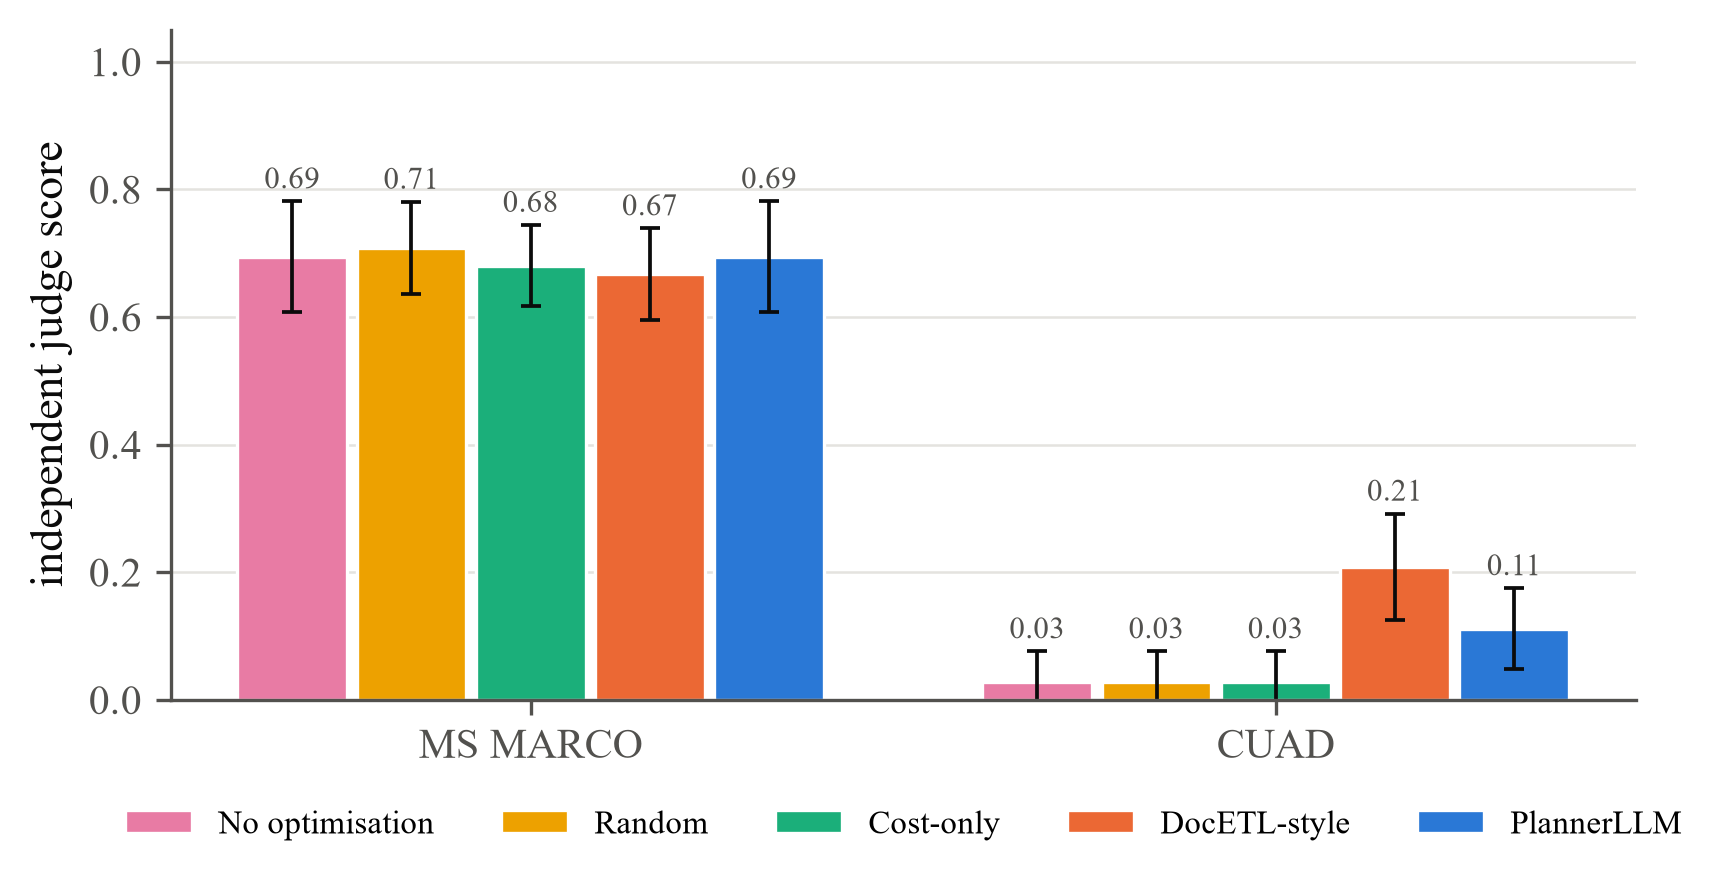

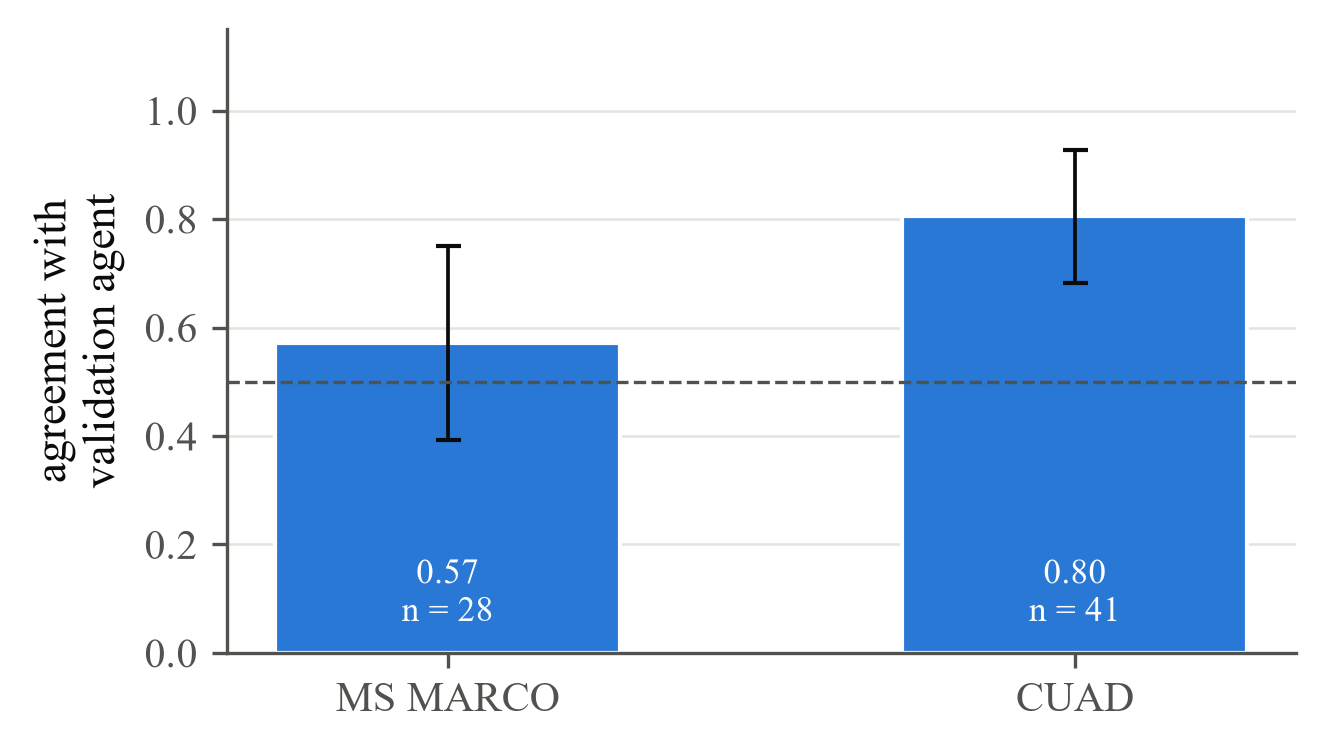

In [7]:
print("judge model:", A.get("judge_model"), "| judge tokens:", A.get("judge_tokens"))
table(["Workload", "System", "Judge score"], [[WL[r["workload"]], SYS[r["system"]], ms(r["judge_acc"])] for r in A.get("judge_acc", [])])
table(["Workload", "n answers", "Spearman (primary metric, judge)", "p", "Spearman (token F1, judge)"],
      [[WL[c["workload"]], c["n"], num(c["spearman_metric"]), num(c["p"]), num(c["spearman_f1"])] for c in A.get("metric_judge_corr", [])])
table(["Workload", "n decisions", "Agreement with validation agent", "95% CI", "Cohen's kappa"],
      [[WL.get(v["workload"], "All"), v["n"], num(v["agreement"]),
        "-" if not v["ci95"] else f"[{v['ci95'][0]:.2f}, {v['ci95'][1]:.2f}]", num(v["kappa"])] for v in A.get("validator_agreement", [])])
for f in ("fig_judge_accuracy.png", "fig_validator_agreement.png"):
    if (AGG / f).exists():
        display(Image(filename=str(AGG / f), width=650))

## 4. VoI gate and θ sweep

logged gate decisions (pooled over seeds): 228 | expected calibration error: 0.269


θ,Precision,Recall,Validation spend avoided
0.1,0.148 ± 0.051,1.000 ± 0.000,0.143 ± 0.057
0.25,0.145 ± 0.045,0.979 ± 0.036,0.152 ± 0.062
0.5,0.151 ± 0.049,0.958 ± 0.072,0.217 ± 0.083
1.0,0.155 ± 0.051,0.938 ± 0.108,0.265 ± 0.108
2.0,0.147 ± 0.053,0.806 ± 0.173,0.350 ± 0.068
4.0,0.161 ± 0.073,0.681 ± 0.064,0.501 ± 0.112
8.0,0.124 ± 0.014,0.333 ± 0.191,0.730 ± 0.126


Workload,θ,Score,Opt. tokens / task,Gate skips
MS MARCO,0.25,0.218 ± 0.044,38505 ± 9226,1.5 ± 1.5
MS MARCO,0.5,0.218 ± 0.044,38505 ± 9226,1.5 ± 1.5
MS MARCO,1.0,0.218 ± 0.044,32496 ± 4799,2.0 ± 1.8
MS MARCO,2.0,0.218 ± 0.044,31580 ± 6239,2.2 ± 2.0
MS MARCO,4.0,0.218 ± 0.044,30677 ± 6205,2.3 ± 1.8
CUAD,0.25,0.190 ± 0.056,31050 ± 6379,1.0 ± 0.9
CUAD,0.5,0.120 ± 0.066,29547 ± 4900,1.3 ± 0.8
CUAD,1.0,0.120 ± 0.066,29228 ± 4680,1.5 ± 1.0
CUAD,2.0,0.097 ± 0.061,26268 ± 5607,2.2 ± 2.1
CUAD,4.0,0.163 ± 0.079,18106 ± 2596,3.5 ± 1.8


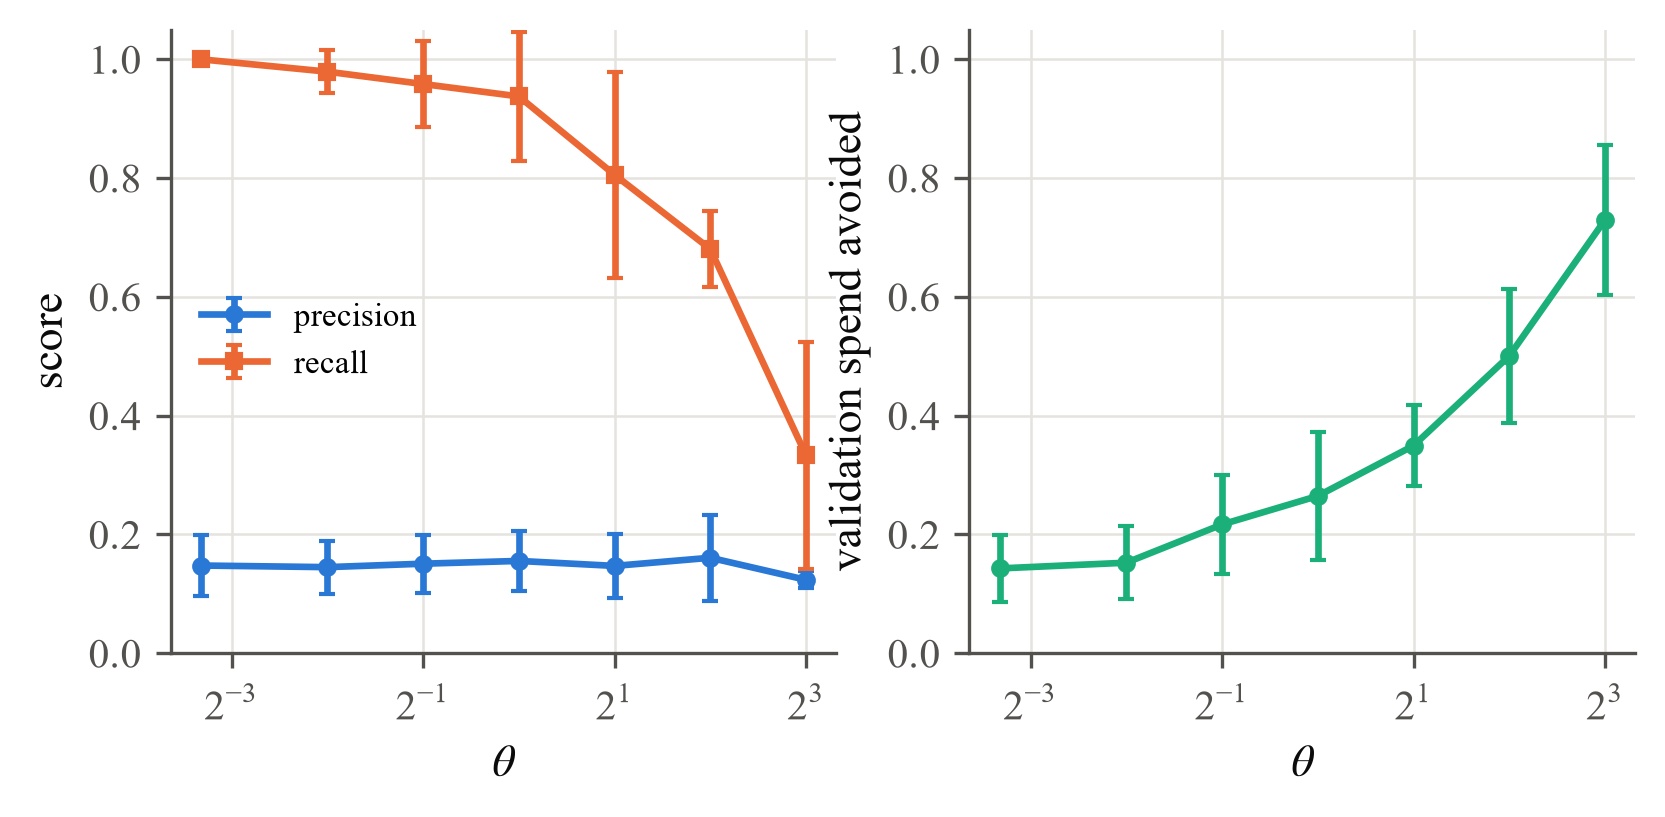

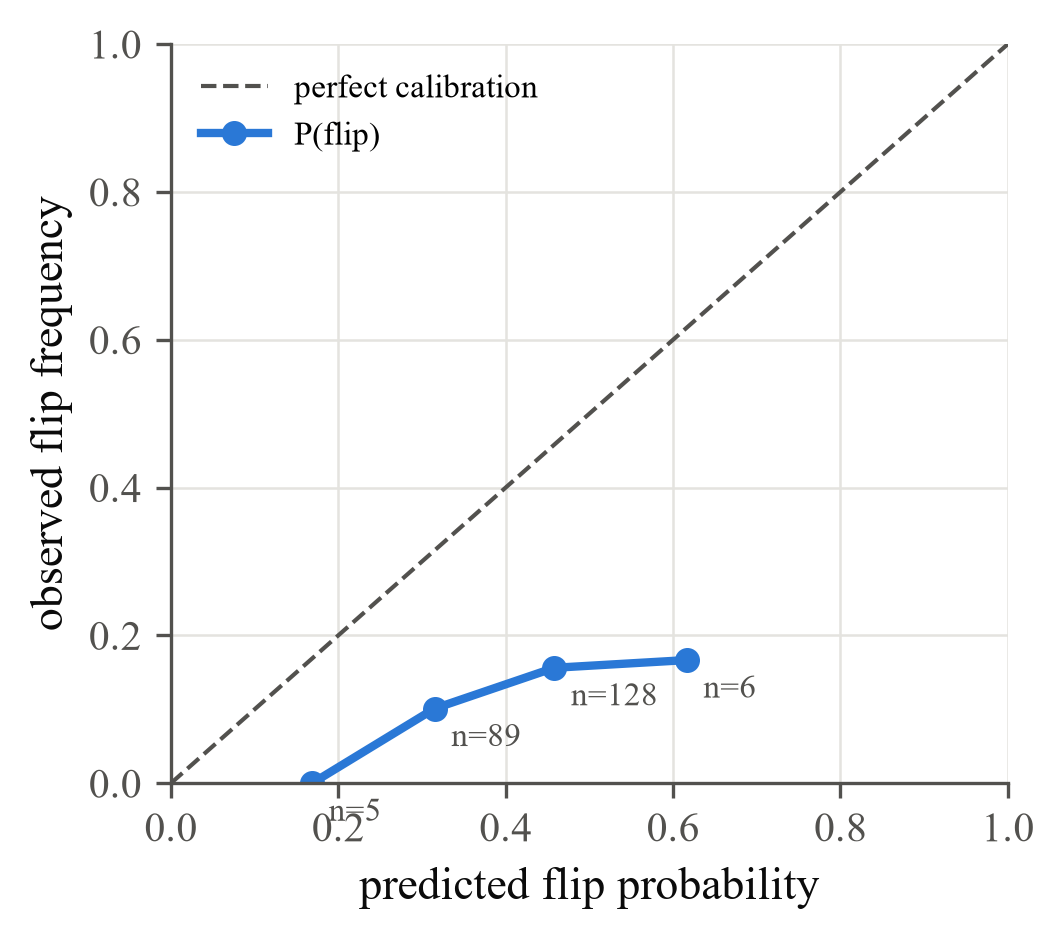

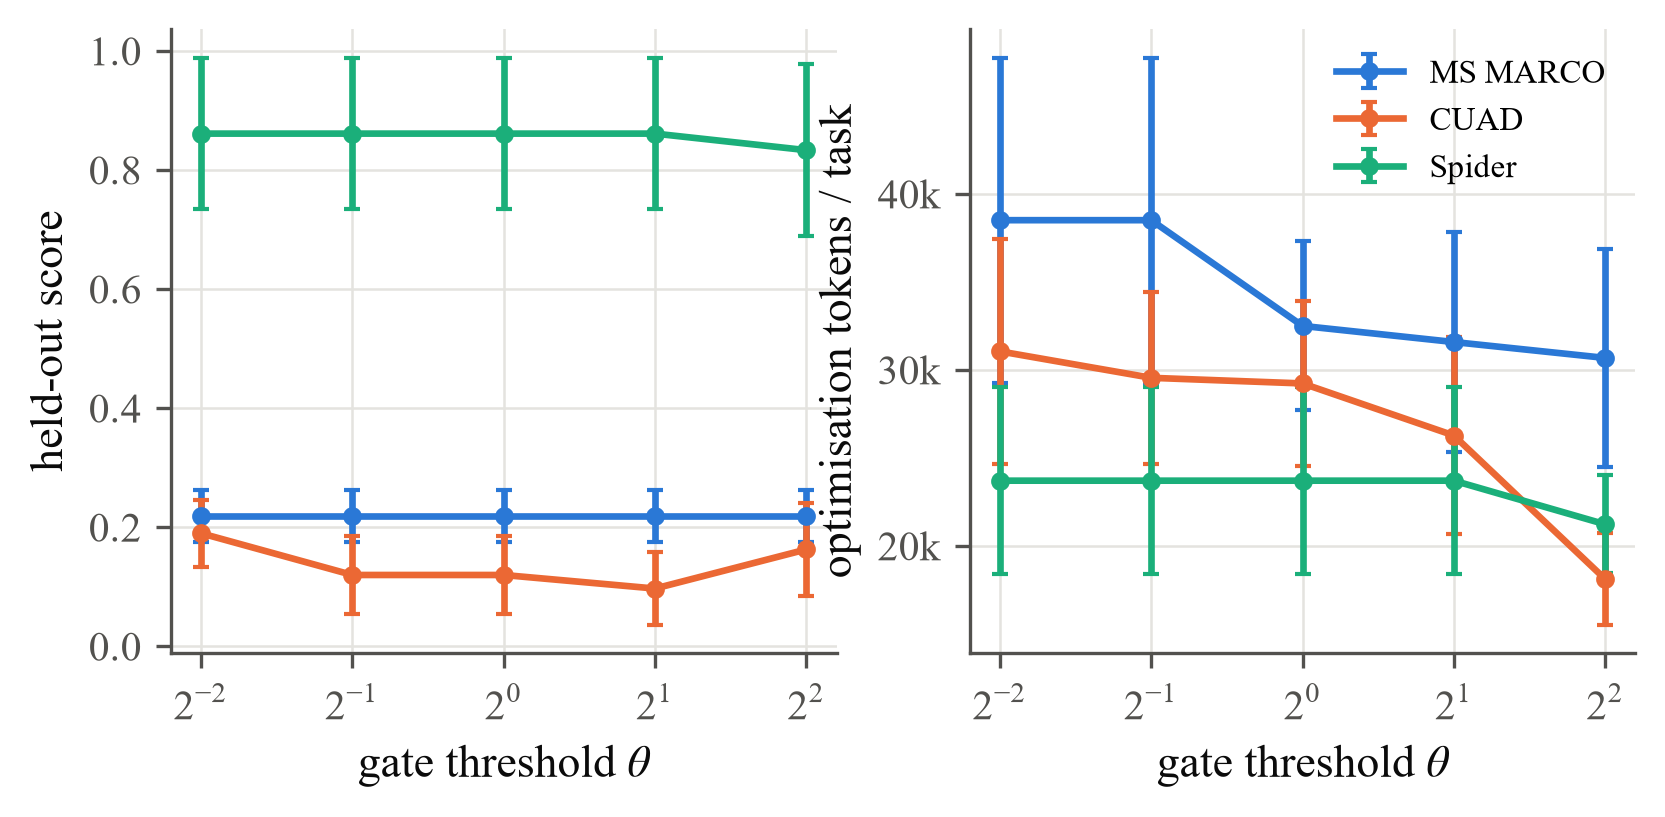

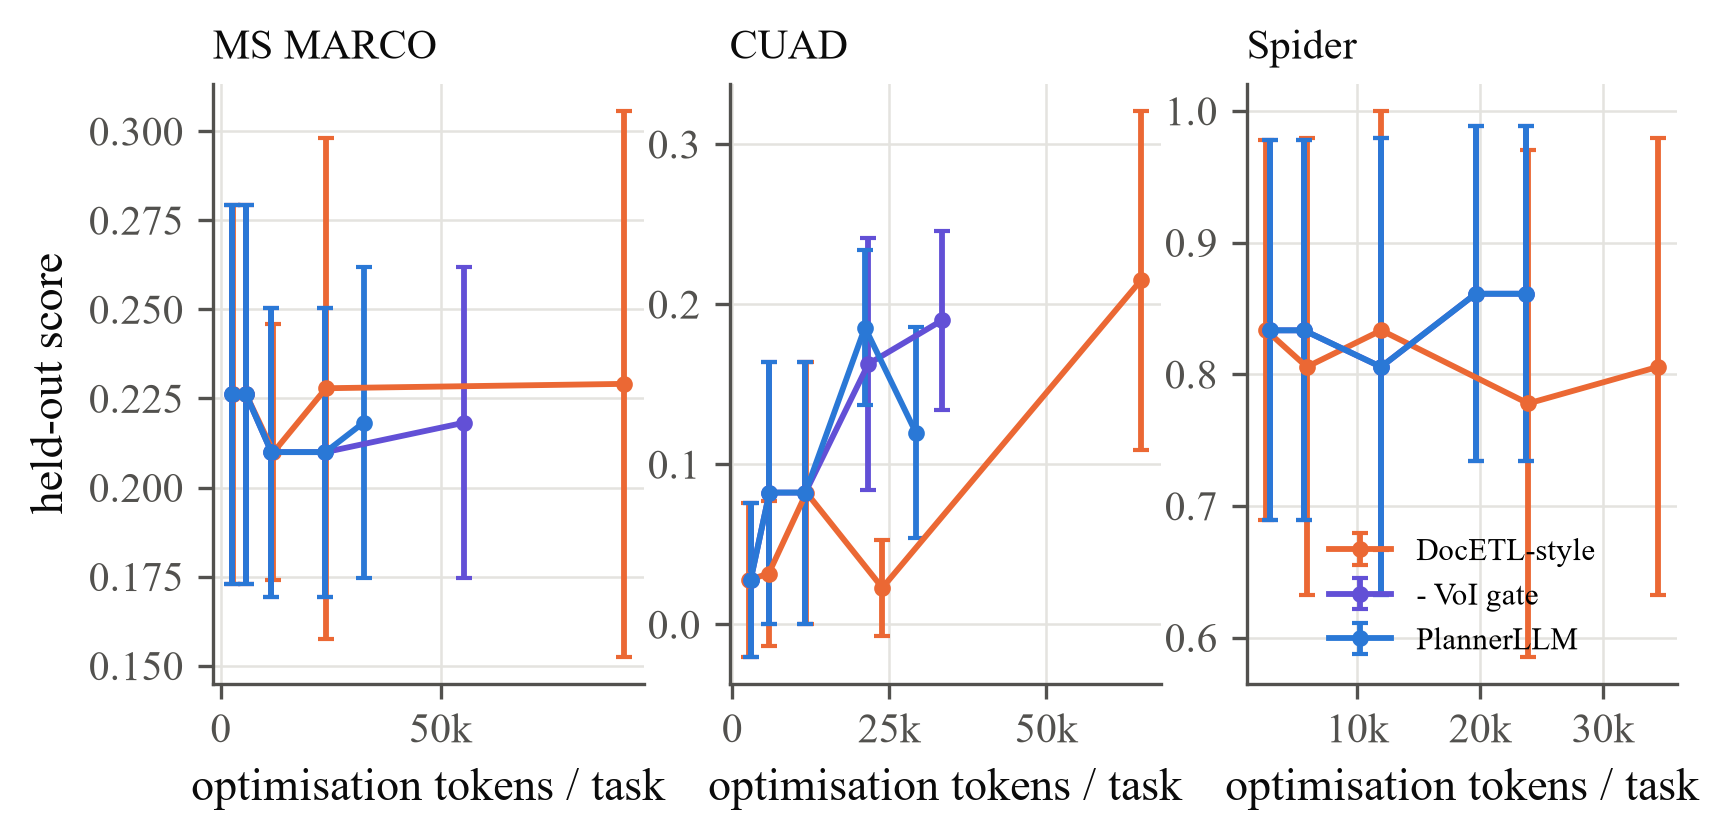

In [8]:
print("logged gate decisions (pooled over seeds):", A["gate_n_decisions"], "| expected calibration error:", num(A["gate_ece"]))
table(["θ", "Precision", "Recall", "Validation spend avoided"],
      [[g["theta"], ms(g["precision"]), ms(g["recall"]), ms(g["spend_saved"])] for g in A["gate"]])
table(["Workload", "θ", "Score", "Opt. tokens / task", "Gate skips"],
      [[WL[p["workload"]], p["theta"], ms(p["accuracy"]), ms(p["opt_tokens"], 0), ms(p["gate_skips"], 1)] for p in A["theta_sweep"]])
for f in ("fig_gate_pr.png", "fig_gate_calibration.png", "fig_theta_sweep.png", "fig_pareto_budget.png"):
    display(Image(filename=str(AGG / f), width=650))

## 5. Plan memory

repeated-shape hit rate, mean over workloads: 0.159 ± 0.180


Workload,Phase,Hit rate,Opt. tokens / task,Score,Audited hits,Reuse accuracy
MS MARCO,first-seen,0.000 ± 0.000,32496 ± 4799,0.218 ± 0.044,0,-
MS MARCO,repeated,0.367 ± 0.473,21542 ± 7686,0.218 ± 0.044,15,1.000
MS MARCO,prompt_edit,0.000 ± 0.000,17630 ± 10405,0.272 ± 0.085,0,-
MS MARCO,config_change,0.000 ± 0.000,21442 ± 9722,0.222 ± 0.037,0,-
CUAD,first-seen,0.000 ± 0.000,29228 ± 4680,0.120 ± 0.066,0,-
CUAD,repeated,0.111 ± 0.102,24963 ± 5995,0.120 ± 0.066,10,1.000
CUAD,prompt_edit,0.000 ± 0.000,21696 ± 7672,0.163 ± 0.079,0,-
CUAD,config_change,0.000 ± 0.000,26002 ± 9238,0.163 ± 0.119,0,-
Spider,first-seen,0.000 ± 0.000,23702 ± 5297,0.861 ± 0.127,0,-
Spider,repeated,0.000 ± 0.000,25383 ± 1980,0.861 ± 0.127,0,-


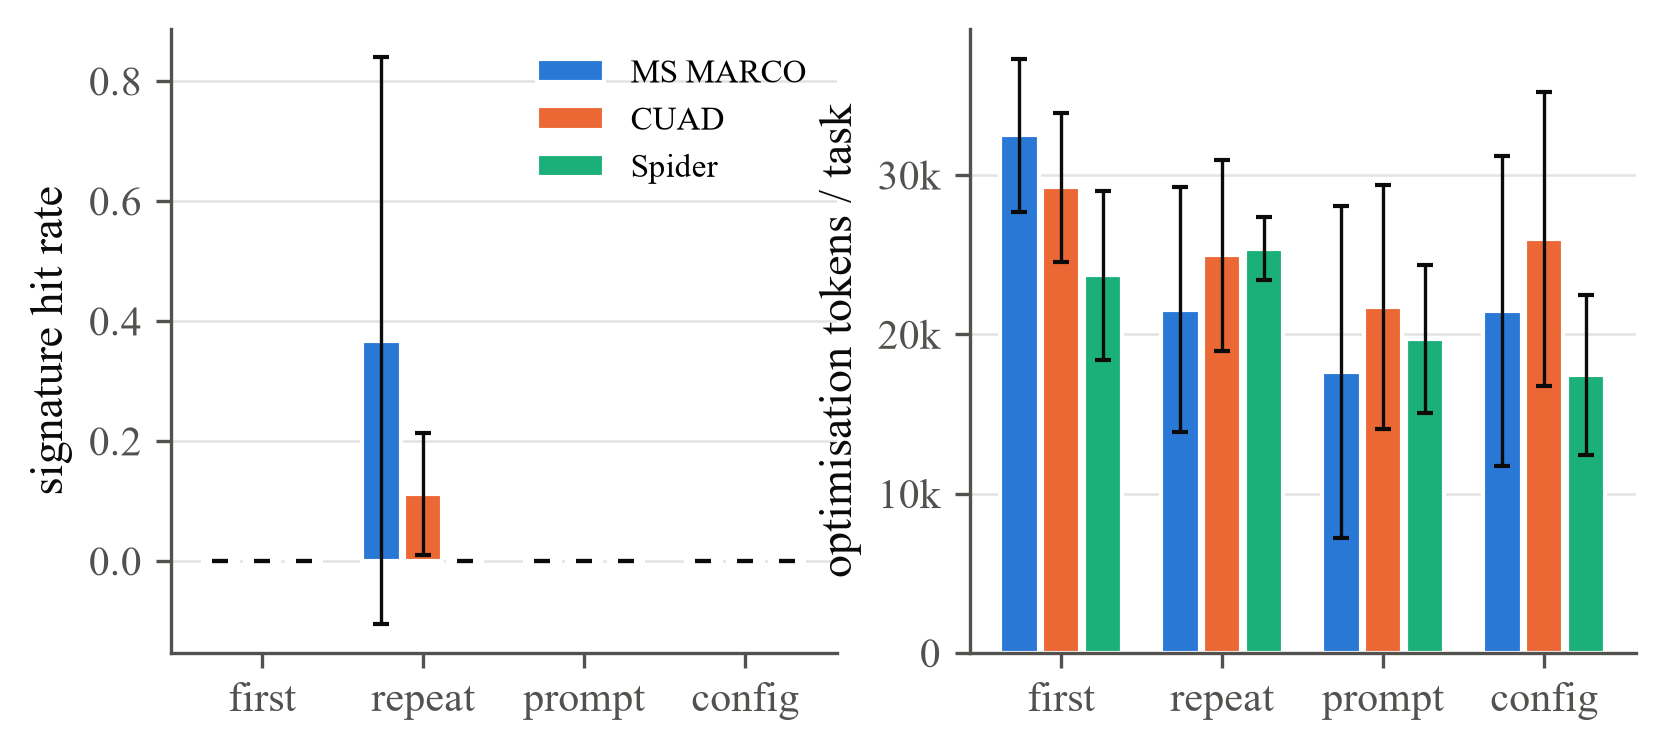

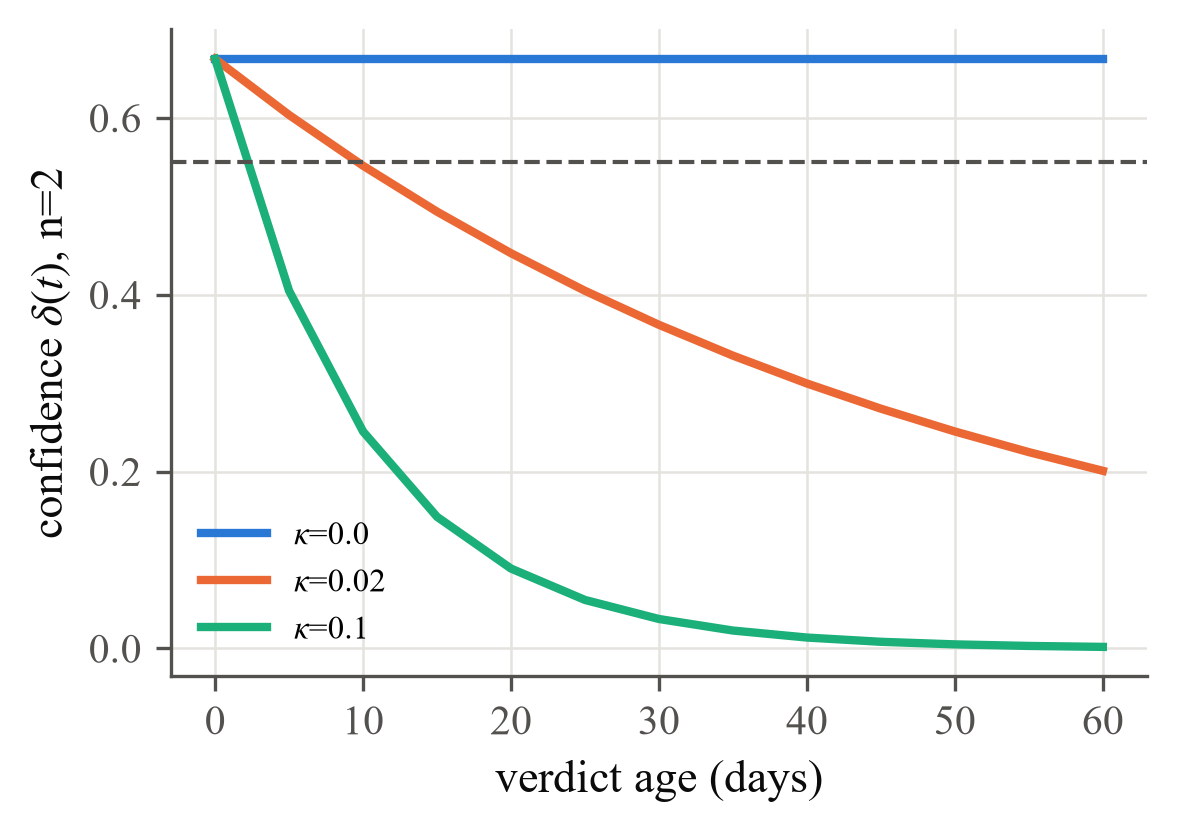

In [9]:
table(["Workload", "Phase", "Hit rate", "Opt. tokens / task", "Score", "Audited hits", "Reuse accuracy"],
      [[WL[m["workload"]], m["phase"], ms(m["hit_rate"]), ms(m["opt_tokens"], 0), ms(m["accuracy"]), m["n_audited"],
        num(m["reuse_accuracy"])] for m in A["memory"]])
print("repeated-shape hit rate, mean over workloads:", ms(A["memory_repeat_hit_rate"]))
for f in ("fig_memory_hits.png", "fig_memory_decay.png"):
    display(Image(filename=str(AGG / f), width=650))

## 6. Cost model

telemetry rows per seed: 65 ± 1


Split,Target,Model,Median q-error,P90 q-error
cv,ms,hybrid,1.12 ± 0.04,1.57 ± 0.14
cv,ms,neural,1.16 ± 0.04,1.63 ± 0.11
cv,ms,symbolic,4.45 ± 0.50,8.06 ± 1.05
cv,usd,hybrid,1.07 ± 0.02,1.34 ± 0.11
cv,usd,neural,1.07 ± 0.04,1.34 ± 0.17
cv,usd,symbolic,1.26 ± 0.06,1.83 ± 0.10
zero-shot:cuad,ms,hybrid,1.68 ± 0.12,2.39 ± 0.17
zero-shot:cuad,ms,neural,2.01 ± 0.25,3.20 ± 0.24
zero-shot:cuad,ms,symbolic,6.75 ± 0.67,9.34 ± 0.54
zero-shot:cuad,usd,hybrid,1.58 ± 0.15,2.14 ± 0.31


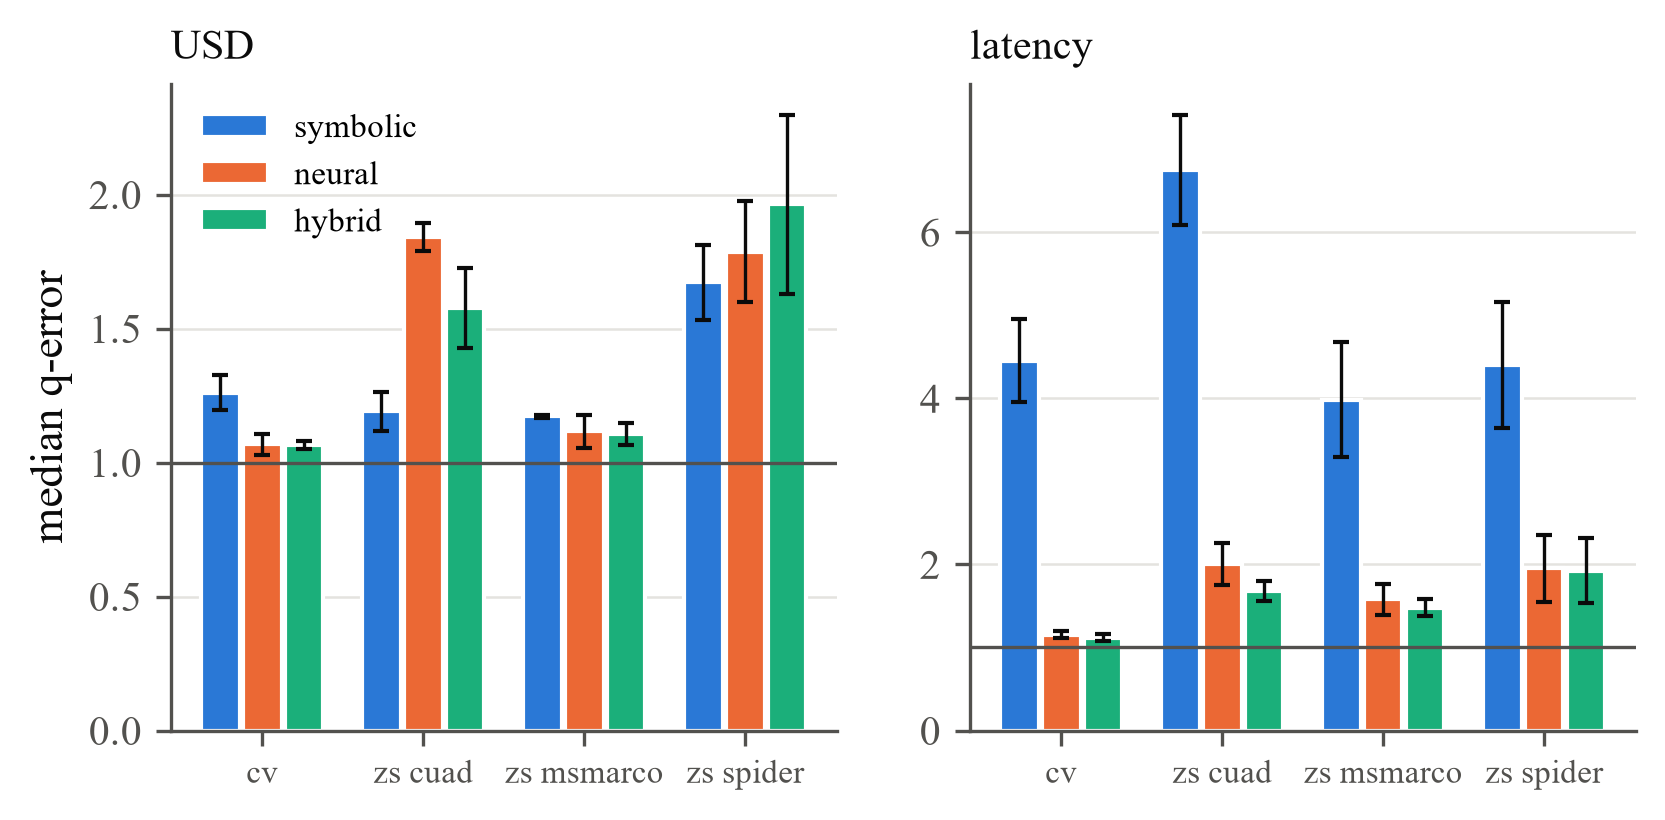

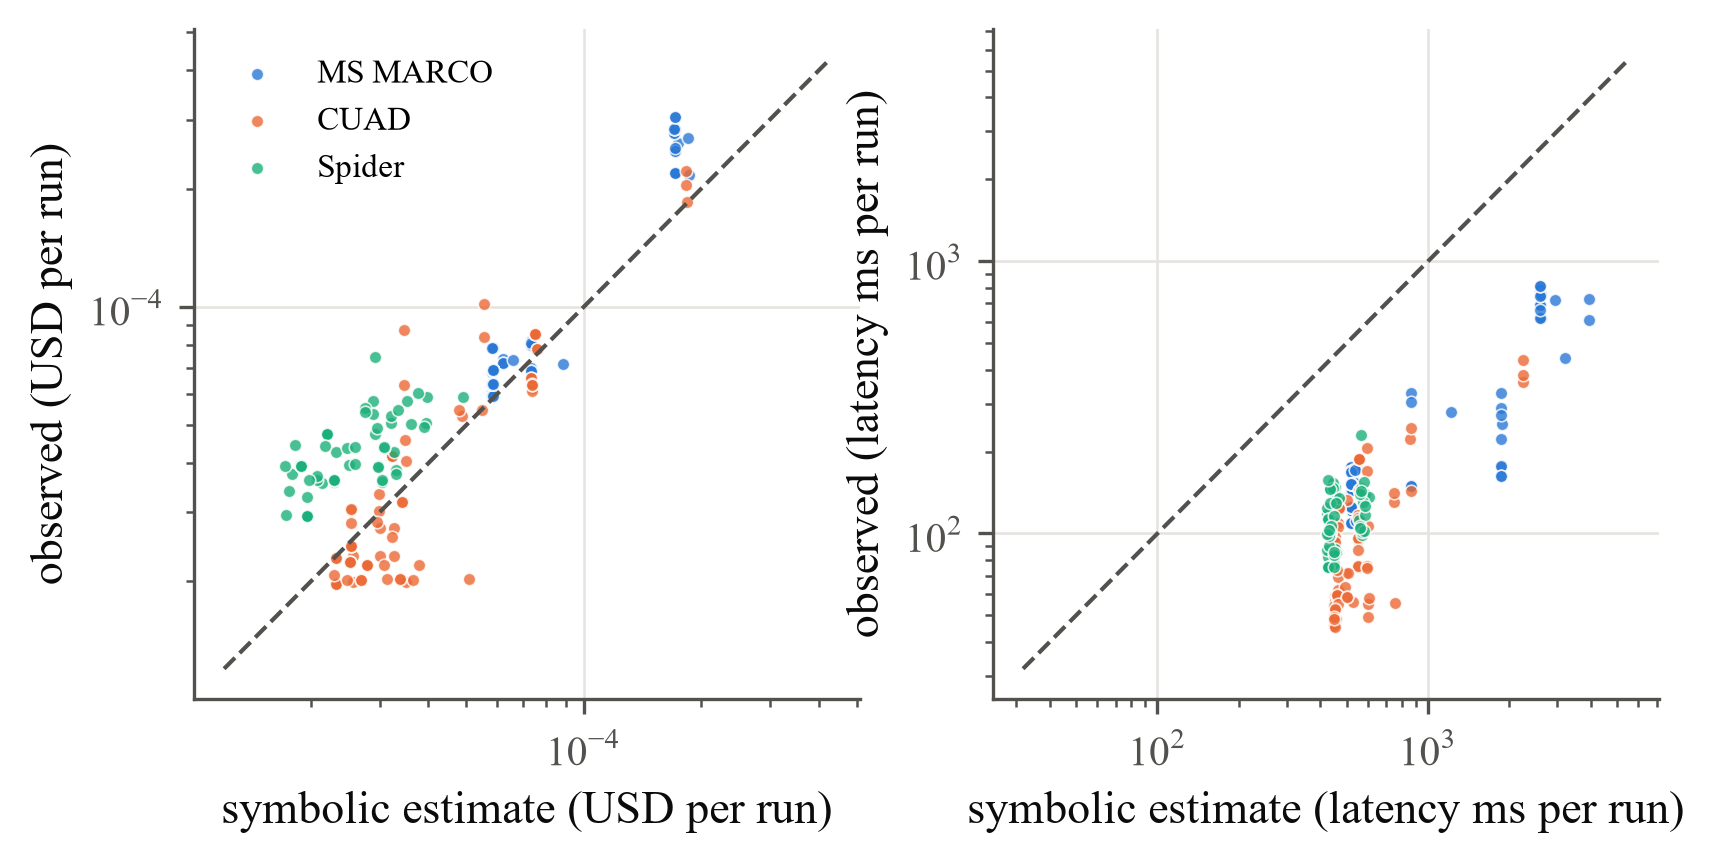

In [10]:
print("telemetry rows per seed:", ms(A["cost_samples"], 0))
table(["Split", "Target", "Model", "Median q-error", "P90 q-error"],
      [[c["split"], c["target"], c["model"], ms(c["median_q"], 2), ms(c["p90_q"], 2)] for c in A["cost_model"]])
for f in ("fig_cost_qerror.png", "fig_cost_scatter.png"):
    display(Image(filename=str(AGG / f), width=650))

## 7. Latency

Workload,Index,Selectivity,Filtered recall,Post-filter recall,Filtered ms,Post-filter ms
MS MARCO,flat,0.1979,1.00,0.98,1.63,1.82
MS MARCO,hnsw,0.1979,1.00,0.98,1.76,1.71
MS MARCO,ivf,0.1979,1.00,0.95,1.66,1.64
CUAD,flat,0.0132,1.00,0.05,1.27,1.43
CUAD,hnsw,0.0132,0.68,0.05,1.39,1.38
CUAD,ivf,0.0132,0.96,0.05,1.30,1.34
Spider,flat,0.0550,1.00,0.82,1.07,1.08
Spider,hnsw,0.0550,1.00,0.82,1.11,1.10
Spider,ivf,0.0550,1.00,0.82,1.08,1.08


Workload,System,LLM service time on the optimisation path (s / task)
MS MARCO,Cost-only,0.5 ± 0.0
MS MARCO,DocETL-style,27.6 ± 4.6
MS MARCO,No optimisation,0.0 ± 0.0
MS MARCO,PlannerLLM,7.6 ± 1.4
MS MARCO,Random,0.0 ± 0.0
CUAD,Cost-only,0.6 ± 0.1
CUAD,DocETL-style,14.8 ± 1.3
CUAD,No optimisation,0.0 ± 0.0
CUAD,PlannerLLM,7.5 ± 0.6
CUAD,Random,0.0 ± 0.0


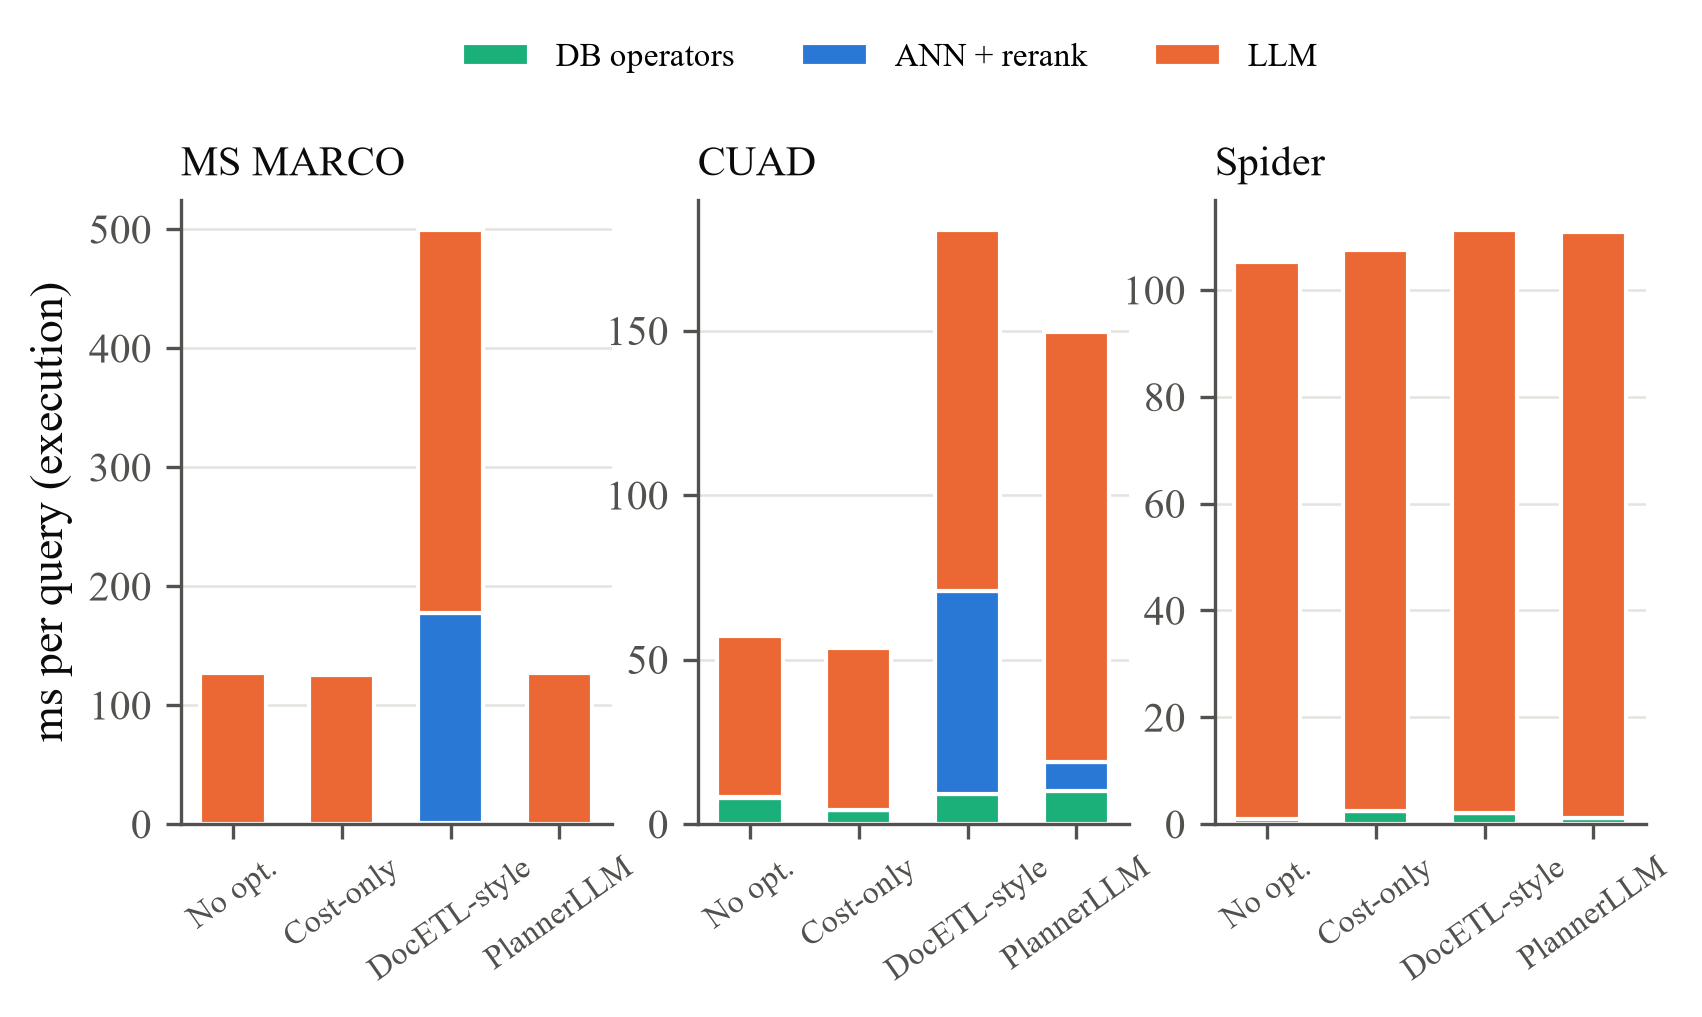

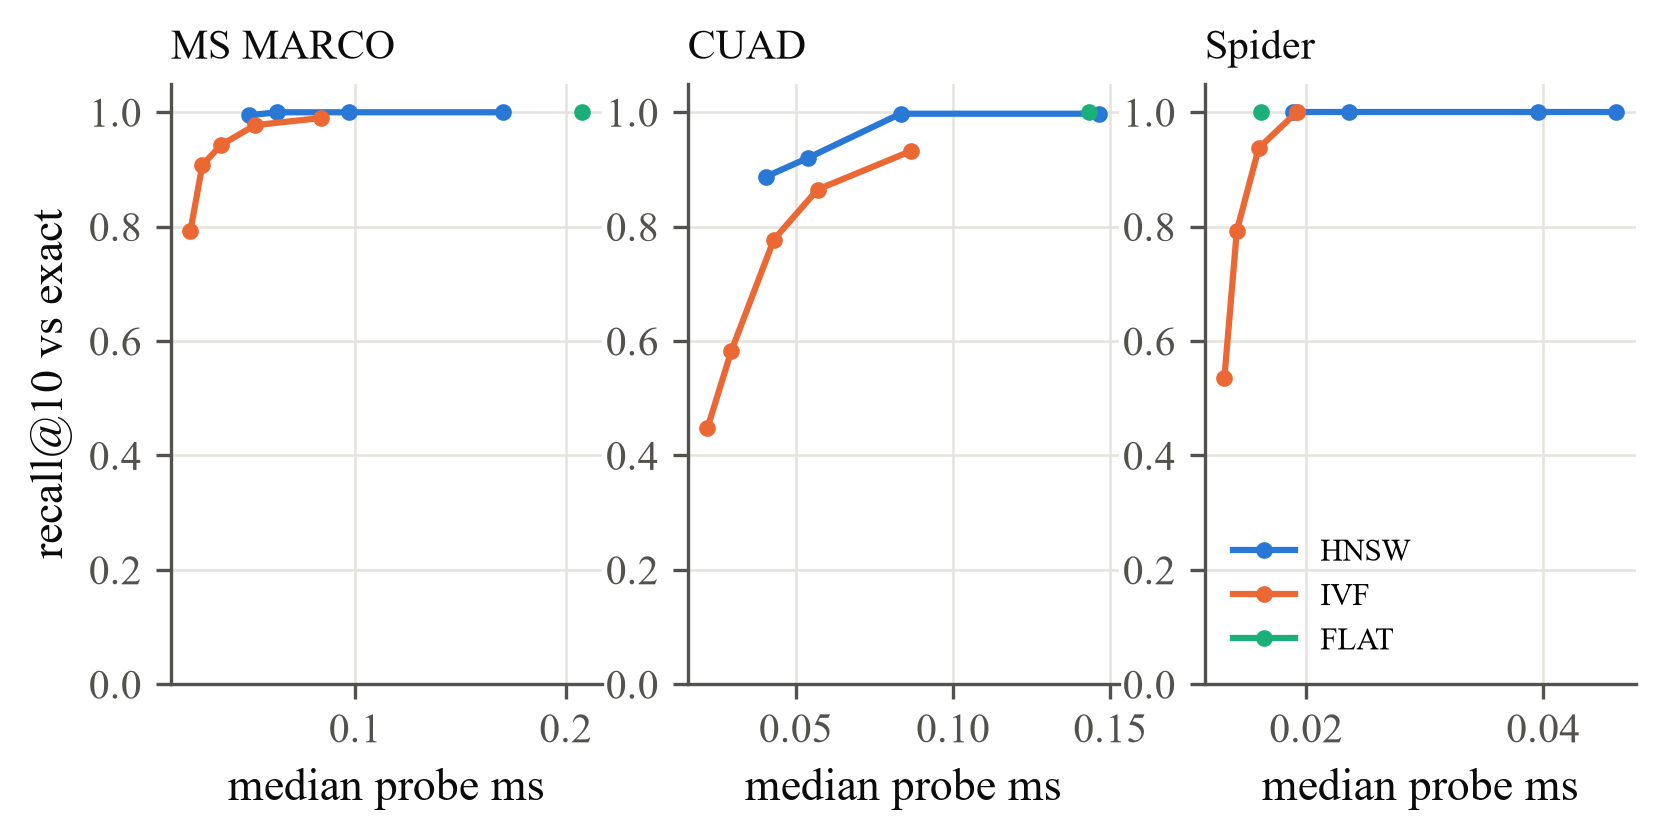

In [11]:
table(["Workload", "Index", "Selectivity", "Filtered recall", "Post-filter recall", "Filtered ms", "Post-filter ms"],
      [[WL[p["workload"]], p["family"], f"{p['sel']:.4f}", num(p["filtered_recall"], 2), num(p["post_recall"], 2),
        num(p["filtered_ms"], 2), num(p["post_ms"], 2)] for p in A["probe"]])
table(["Workload", "System", "LLM service time on the optimisation path (s / task)"],
      [[WL[x["workload"]], SYS[x["system"]], ms(x["opt_llm_s"], 1)] for x in A["llm_time"]])
for f in ("fig_latency_breakdown.png", "fig_ann_sweep.png"):
    display(Image(filename=str(AGG / f), width=650))

## 8. Ablations (identical token budget, second pass)

budget per task: 20000


Workload,Variant,Score,Opt. tokens / task,Validations,Memory hits,Gate skips
MS MARCO,PlannerLLM,0.210 ± 0.041,18192 ± 2461,1.8 ± 0.3,0.3 ± 0.6,1.0 ± 1.7
MS MARCO,without VoI gate,0.210 ± 0.041,19681 ± 133,1.8 ± 0.3,0.3 ± 0.6,0.0 ± 0.0
MS MARCO,without plan memory,0.210 ± 0.041,19512 ± 453,2.5 ± 0.0,0.0 ± 0.0,1.0 ± 1.0
MS MARCO,symbolic cost only,0.210 ± 0.041,18192 ± 2461,1.8 ± 0.3,0.3 ± 0.6,1.0 ± 1.7
MS MARCO,neural cost only,0.210 ± 0.041,18192 ± 2461,1.8 ± 0.3,0.3 ± 0.6,1.0 ± 1.7
CUAD,PlannerLLM,0.185 ± 0.048,17514 ± 2467,3.0 ± 0.9,1.2 ± 1.3,1.8 ± 1.4
CUAD,without VoI gate,0.185 ± 0.048,18782 ± 1249,3.7 ± 0.8,1.7 ± 2.1,0.0 ± 0.0
CUAD,without plan memory,0.105 ± 0.091,13886 ± 4145,2.8 ± 0.8,0.0 ± 0.0,3.7 ± 2.1
CUAD,symbolic cost only,0.185 ± 0.048,17514 ± 2467,3.0 ± 0.9,1.2 ± 1.3,1.8 ± 1.4
CUAD,neural cost only,0.185 ± 0.048,17514 ± 2467,3.0 ± 0.9,1.2 ± 1.3,1.8 ± 1.4


Workload,Variant,Tokens: full minus variant,95% CI,p,Score: full minus variant,p
MS MARCO,without VoI gate,"-1,490","[-4,500, 30]",1.000,0.000,1.000
MS MARCO,without plan memory,"-1,320","[-4,018, 263]",0.438,0.000,1.000
MS MARCO,symbolic cost only,0,"[0, 0]",1.000,0.000,1.000
MS MARCO,neural cost only,0,"[0, 0]",1.000,0.000,1.000
CUAD,without VoI gate,"-1,268","[-2,935, 2]",0.188,0.000,1.000
CUAD,without plan memory,"3,628","[874, 7,075]",0.094,0.080,1.000
CUAD,symbolic cost only,0,"[0, 0]",1.000,0.000,1.000
CUAD,neural cost only,0,"[0, 0]",1.000,0.000,1.000
Spider,without VoI gate,-480,"[-1,439, 0]",1.000,0.000,1.000
Spider,without plan memory,346,"[117, 614]",0.125,0.000,1.000


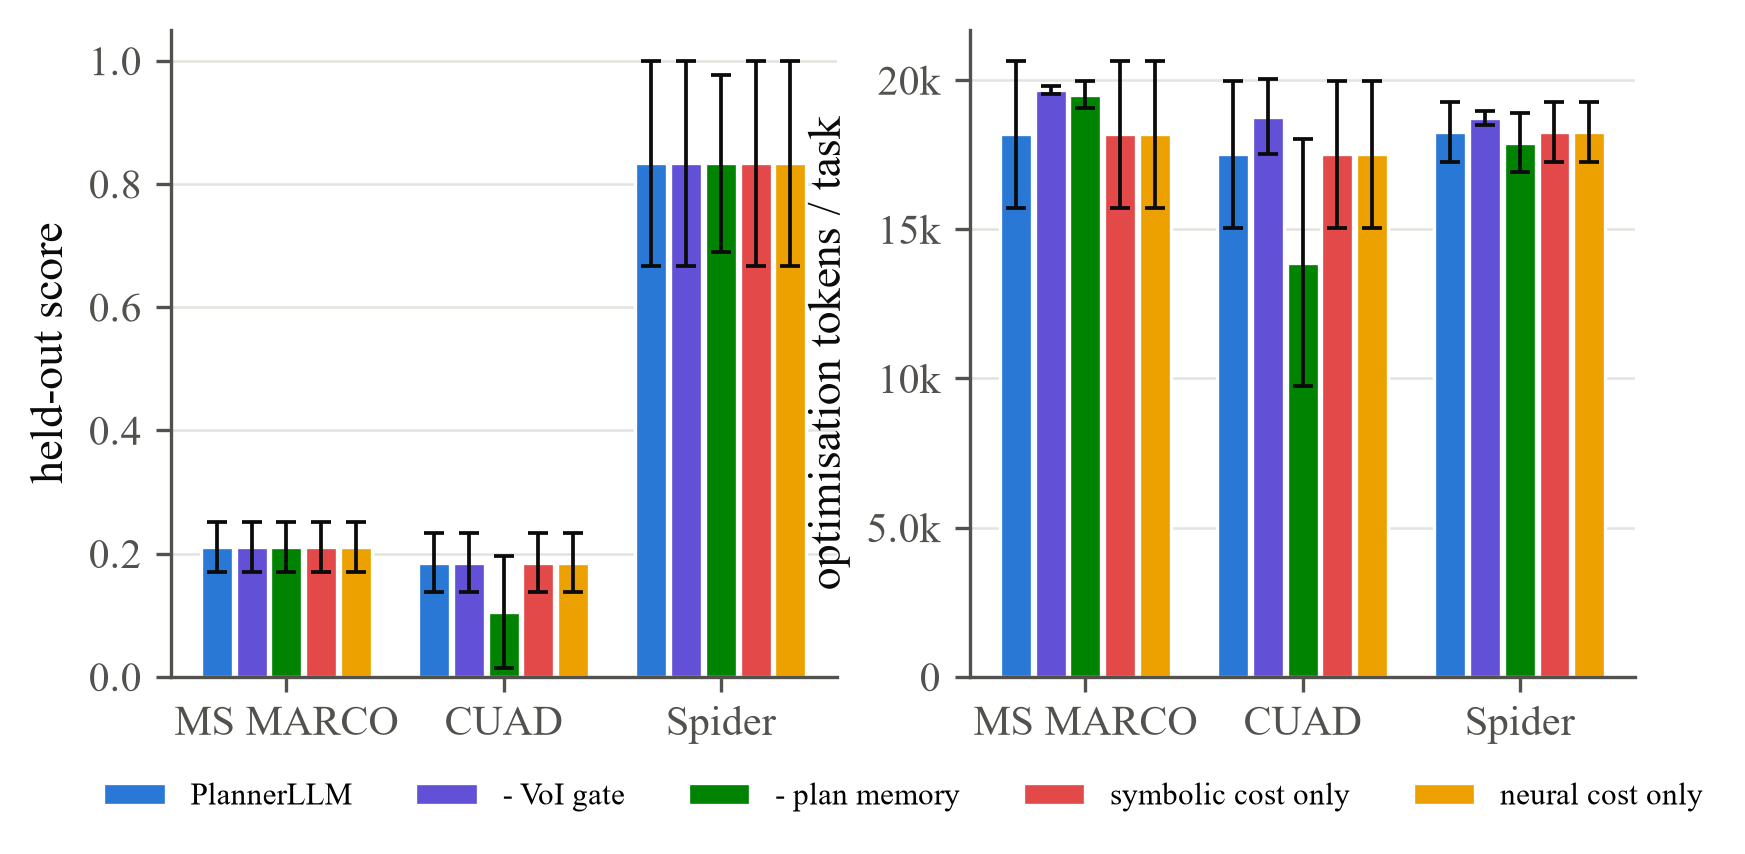

In [12]:
print("budget per task:", A["ablation_budget"])
table(["Workload", "Variant", "Score", "Opt. tokens / task", "Validations", "Memory hits", "Gate skips"],
      [[WL[a["workload"]], SYS[a["variant"]], ms(a["accuracy"]), ms(a["opt_tokens"], 0), ms(a["n_validations"], 1),
        ms(a["n_memory_hits"], 1), ms(a["n_gate_skips"], 1)] for a in A["ablation"]])
table(["Workload", "Variant", "Tokens: full minus variant", "95% CI", "p", "Score: full minus variant", "p"],
      [[WL[t["workload"]], SYS[t["variant"]], num(t["tokens"]["mean_diff"], 0),
        "-" if not t["tokens"]["ci95"] else f"[{t['tokens']['ci95'][0]:,.0f}, {t['tokens']['ci95'][1]:,.0f}]",
        num(t["tokens"]["p_wilcoxon"]), num(t["accuracy"]["mean_diff"]), num(t["accuracy"]["p_wilcoxon"])]
       for t in A["ablation_tests"]])
display(Image(filename=str(AGG / "fig_ablation.png"), width=700))

## 9. Consistency check

The headline numbers are recomputed from the raw per-seed files with separate code and compared with the aggregate.

In [13]:
from plannerllm.eval.verify import check_aggregate
checks = check_aggregate(TAG)
bad = [c for c in checks if not c["ok"]]
for c in checks:
    print(("ok   " if c["ok"] else "FAIL ") + c["check"], c["raw"], c["aggregate"])
print()
print("ALL CONSISTENCY CHECKS PASSED" if not bad else f"{len(bad)} CHECKS FAILED")

ok   raw vs aggregate: baselines.cuad.cost_only.accuracy 0.027777777777777776 0.027777777777777776
ok   raw vs aggregate: baselines.cuad.cost_only.n_validations 0.0 0.0
ok   raw vs aggregate: baselines.cuad.cost_only.opt_tokens 1622.1666666666667 1622.1666666666667
ok   raw vs aggregate: baselines.cuad.docetl.accuracy 0.21493343820445202 0.21493343820445202
ok   raw vs aggregate: baselines.cuad.docetl.n_validations 18.0 18.0
ok   raw vs aggregate: baselines.cuad.docetl.opt_tokens 65042.166666666664 65042.166666666664
ok   raw vs aggregate: baselines.cuad.no_opt.accuracy 0.027777777777777776 0.027777777777777776
ok   raw vs aggregate: baselines.cuad.no_opt.n_validations 0.0 0.0
ok   raw vs aggregate: baselines.cuad.no_opt.opt_tokens 0.0 0.0
ok   raw vs aggregate: baselines.cuad.plannerllm.accuracy 0.1197760772660625 0.1197760772660625
ok   raw vs aggregate: baselines.cuad.plannerllm.n_validations 6.833333333333333 6.833333333333333
ok   raw vs aggregate: baselines.cuad.plannerllm.opt_to

## Notebook execution results

Seed,Completed experiments,Missing experiments
0,9,None
1,9,None
2,9,None


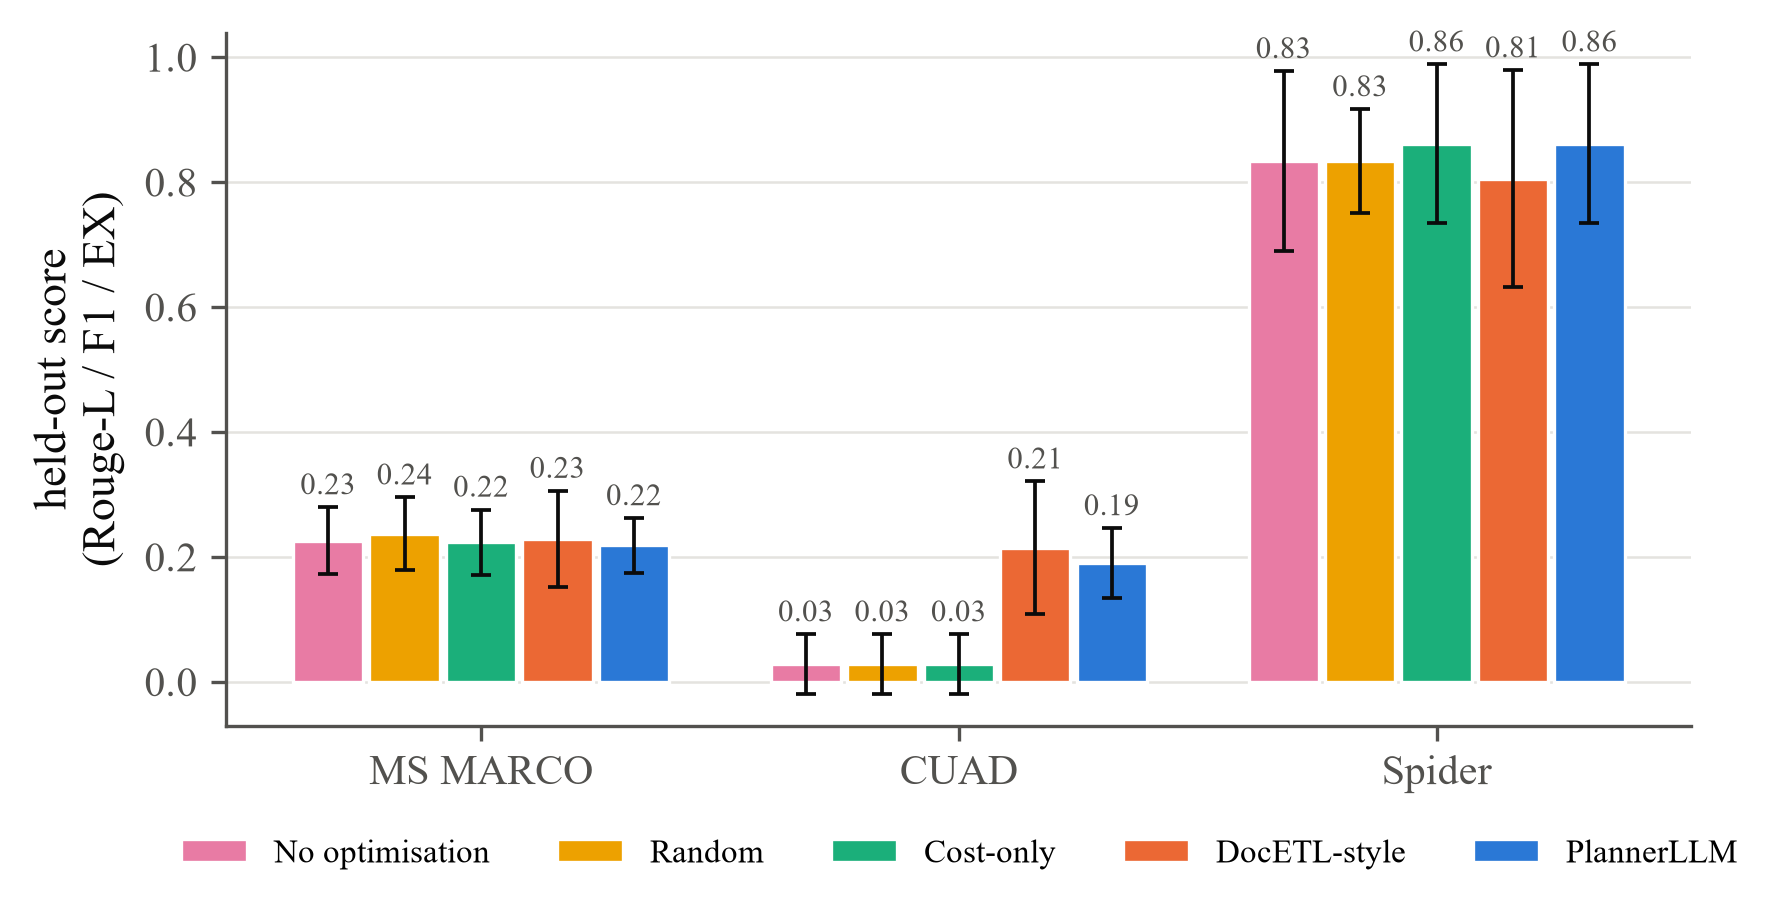

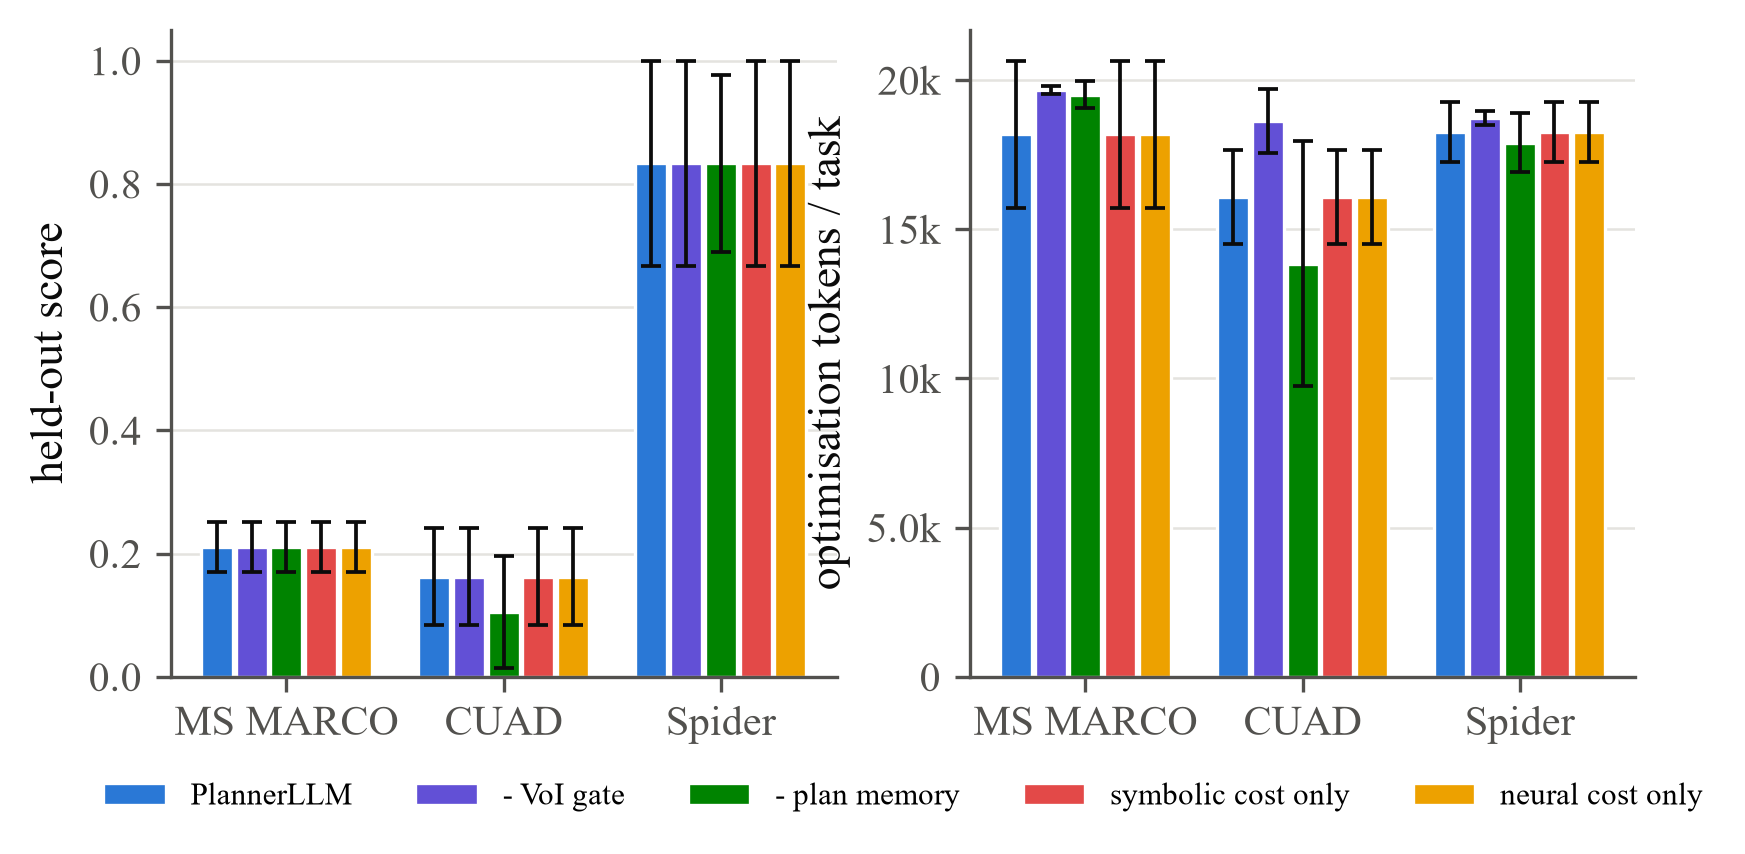

In [14]:
reproduction = ROOT / "reproduced_runs" / "recorded_groq"
expected_experiments = ("baselines", "pareto", "gate", "memory", "cost_model", "latency", "ablation", "transcripts", "judge")
table(["Seed", "Completed experiments", "Missing experiments"], [
    [seed, sum((reproduction / f"{TAG}_seed{seed}" / f"{name}.json").exists() for name in expected_experiments),
     ", ".join(name for name in expected_experiments
               if not (reproduction / f"{TAG}_seed{seed}" / f"{name}.json").exists()) or "None"]
    for seed in (0, 1, 2)
])
for name in ("fig_baselines_accuracy.png", "fig_ablation.png"):
    path = reproduction / f"{TAG}_aggregate" / name
    if path.exists():
        display(Image(filename=str(path)))
